# PRML Lab 2 — Decision Trees
**Aryan Tiwari (B20AI056)** · CSL2050 Pattern Recognition & Machine Learning · Winter 2022

Roll number 56 is even, so the split criterion used throughout Question 1 is **entropy** (information gain).

In [1]:
import json
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error

SEED = 56
np.random.seed(SEED)
sns.set_theme(style='whitegrid')
results = {}

def savefig(name):
    plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')

# Question 1 — Classification tree from scratch (Penguins)

### 1. Pre-processing, visualisation, encoding and split

In [2]:
peng = pd.read_csv('data/penguins.csv')
print(peng.shape)
print(peng.isna().sum())
peng.head()

(344, 8)
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


- The two rows with **no measurements at all** carry no information, so they are dropped.
- `sex` is missing for 9 more rows; it is filled with the most frequent value (mode) rather than losing those samples.
- `year` is the year the penguin was observed — it describes the study, not the bird, so it is dropped to stop the tree from learning a spurious rule.

In [3]:
NUM = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
CAT = ['island', 'sex']
peng = peng.dropna(subset=NUM).drop(columns='year')
peng['sex'] = peng['sex'].fillna(peng['sex'].mode()[0])
print(peng.shape, '| missing left:', peng.isna().sum().sum())
print(peng['species'].value_counts().to_dict())

(342, 7) | missing left: 0
{'Adelie': 151, 'Gentoo': 123, 'Chinstrap': 68}


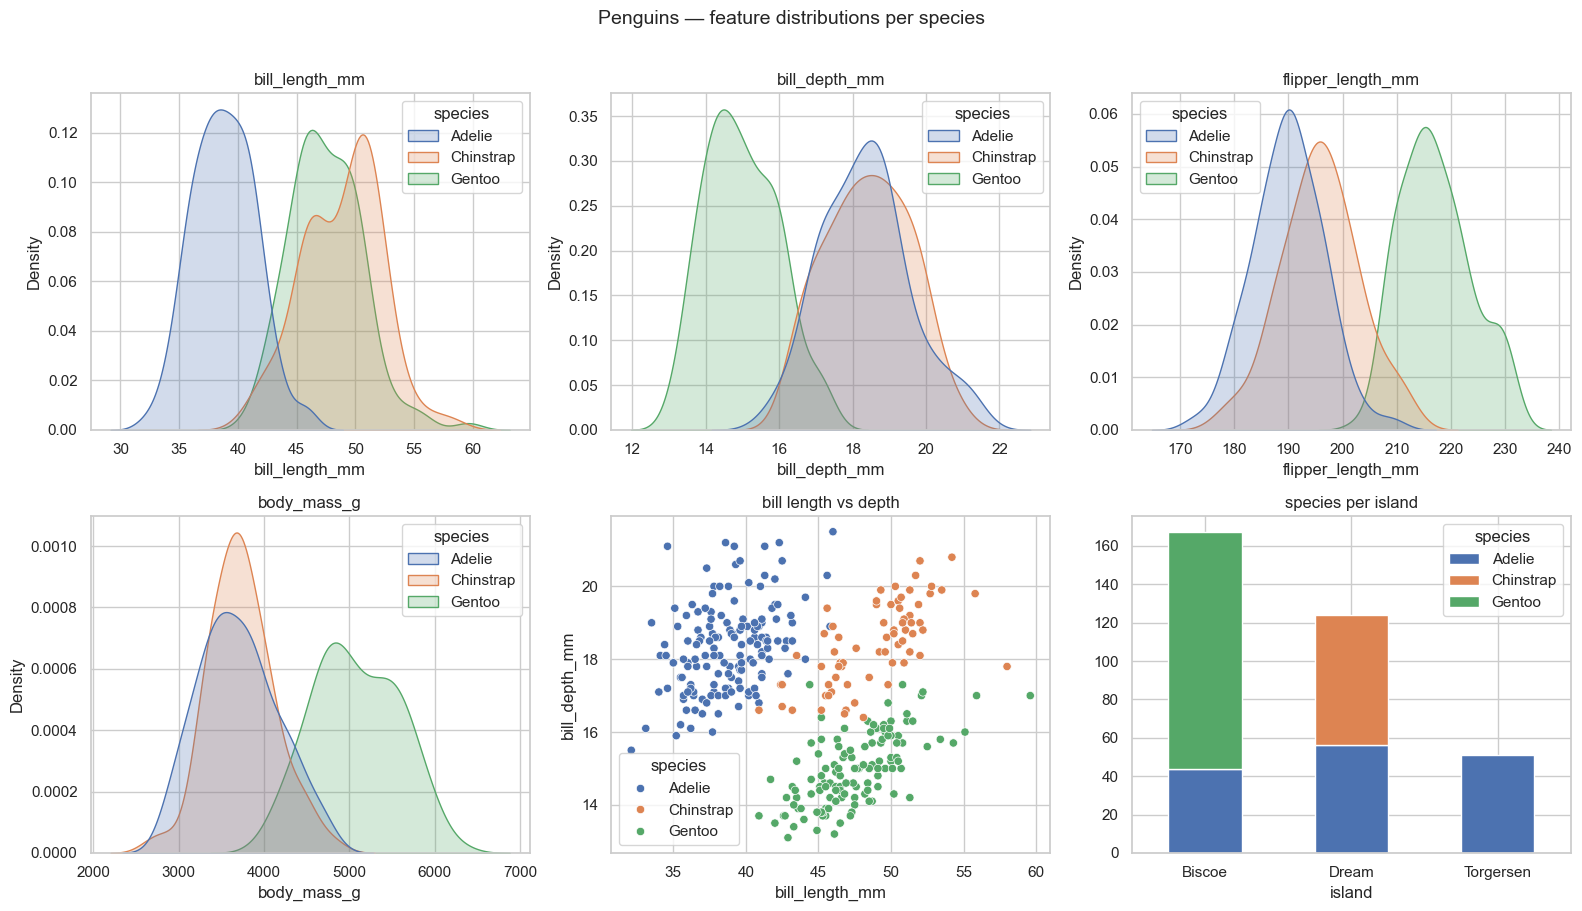

In [4]:
SPECIES = ['Adelie', 'Chinstrap', 'Gentoo']
PAL = dict(zip(SPECIES, sns.color_palette()[:3]))
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
for a, col in zip(ax.flat[:4], NUM):
    sns.kdeplot(data=peng, x=col, hue='species', hue_order=SPECIES, palette=PAL, fill=True, common_norm=False, ax=a)
    a.set_title(col)
sns.scatterplot(data=peng, x='bill_length_mm', y='bill_depth_mm', hue='species', hue_order=SPECIES, palette=PAL, ax=ax[1, 1])
ax[1, 1].set_title('bill length vs depth')
pd.crosstab(peng['island'], peng['species'])[SPECIES].plot.bar(stacked=True, ax=ax[1, 2], rot=0, color=[PAL[s] for s in SPECIES])
ax[1, 2].set_title('species per island')
plt.suptitle('Penguins — feature distributions per species', y=1.01, fontsize=14)
plt.tight_layout(); savefig('q1_eda'); plt.show()

Observations: flipper length and body mass cleanly separate **Gentoo** from the rest; bill length separates **Adelie** from **Chinstrap**; and island is informative (Chinstrap only lives on Dream, Gentoo only on Biscoe).

**Encoding.** The tree works on categorical values directly, so `island` and `sex` are kept as categories and label-encoded to integers (no order is implied, because the tree splits multi-way on each value). Continuous features are converted to 2 bins later by `cont_to_cat`. The data is split 80:20, stratified so each species keeps its proportion in the test set.

In [5]:
data = peng.copy()
for col in CAT:
    data[col] = data[col].astype('category').cat.codes
classes = sorted(data['species'].unique())
X = data[NUM + CAT]
y = data['species'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print('train', X_train.shape, '| test', X_test.shape)

train (273, 6) | test (69, 6)


### 2. Cost function — entropy

$H(S) = -\sum_c p_c \log_2 p_c$. The quality of a split is its **information gain**: parent entropy minus the size-weighted entropy of the children.

In [6]:
def entropy(labels):
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return float(-(p * np.log2(p)).sum())

def weighted_entropy(groups):
    n = sum(len(g) for g in groups)
    return sum(len(g) / n * entropy(g) for g in groups if len(g))

def information_gain(parent, groups):
    return entropy(parent) - weighted_entropy(groups)

print('H(all train labels) =', round(entropy(y_train), 4), '| max for 3 classes =', round(np.log2(3), 4))

H(all train labels) = 1.5133 | max for 3 classes = 1.585


### 3. `cont_to_cat()` — binarising continuous features
Each continuous feature is handled independently. Candidate thresholds are the midpoints between consecutive distinct sorted values; the threshold with the **lowest weighted entropy** (highest information gain) wins. Thresholds are learnt on the training set only and then applied unchanged to the test set.

In [7]:
def best_threshold(values, labels):
    order = np.argsort(values)
    v, lab = values[order], labels[order]
    uniq = np.unique(v)
    best_t, best_h = None, np.inf
    for t in (uniq[:-1] + uniq[1:]) / 2:
        h = weighted_entropy([lab[v <= t], lab[v > t]])
        if h < best_h:
            best_t, best_h = t, h
    return best_t, best_h

def cont_to_cat(X, y, columns, thresholds=None):
    X = X.copy()
    if thresholds is None:
        thresholds = {c: best_threshold(X[c].values, y)[0] for c in columns}
    for c in columns:
        X[c] = (X[c] > thresholds[c]).astype(int)   # 0: <= t, 1: > t
    return X, thresholds

Xtr_cat, thresholds = cont_to_cat(X_train, y_train, NUM)
Xte_cat, _ = cont_to_cat(X_test, y_test, NUM, thresholds)
pd.DataFrame({'threshold': thresholds,
              'info gain': {c: information_gain(y_train, [y_train[Xtr_cat[c] == 0], y_train[Xtr_cat[c] == 1]]) for c in NUM}}).round(3)

,threshold,info gain
bill_length_mm,42.35,0.791
bill_depth_mm,16.35,0.692
flipper_length_mm,207.50,0.797
body_mass_g,4362.50,0.582


### 4–6. Training, stopping criteria and prediction
The tree is ID3-style: at every node it picks the attribute with the highest information gain, creates one child per attribute value, and recurses on each child with that attribute removed.

Stopping rules (task 5):
- **max depth** — a node at `max_depth` becomes a leaf;
- **no information gain** — if the best attainable gain is ≤ `min_gain`, splitting cannot help, so the node becomes a leaf (training has plateaued);
- pure node, or no attributes left.

Each leaf predicts the majority class of its training samples; every internal node also stores its majority class as a fallback for attribute values never seen in training.

In [8]:
class Node:
    def __init__(self, prediction, attribute=None, children=None, depth=0, n=0):
        self.prediction = prediction
        self.attribute = attribute
        self.children = children or {}
        self.depth = depth
        self.n = n

    @property
    def is_leaf(self):
        return self.attribute is None


class DecisionTreeID3:
    def __init__(self, max_depth=5, min_gain=1e-6):
        self.max_depth = max_depth
        self.min_gain = min_gain

    # 4a. attribute giving the best split
    def best_attribute(self, X, y, attributes):
        gains = {a: information_gain(y, [y[X[a].values == v] for v in np.unique(X[a])]) for a in attributes}
        best = max(gains, key=gains.get)
        return best, gains[best]

    # 4b. make the split
    @staticmethod
    def split(X, y, attribute):
        return {v: (X[X[attribute] == v], y[X[attribute].values == v]) for v in np.unique(X[attribute])}

    # 4c. recurse on the new partitions
    def _grow(self, X, y, attributes, depth):
        majority = Counter(y).most_common(1)[0][0]
        node = Node(majority, depth=depth, n=len(y))
        if depth >= self.max_depth or len(set(y)) == 1 or not attributes:
            return node
        attr, gain = self.best_attribute(X, y, attributes)
        if gain <= self.min_gain:
            return node
        node.attribute = attr
        rest = [a for a in attributes if a != attr]
        for value, (Xs, ys) in self.split(X, y, attr).items():
            node.children[value] = self._grow(Xs, ys, rest, depth + 1)
        return node

    def fit(self, X, y):
        self.root = self._grow(X, np.asarray(y), list(X.columns), 0)
        return self

    # 6. classification at test time
    def _predict_one(self, row):
        node = self.root
        while not node.is_leaf:
            child = node.children.get(row[node.attribute])
            if child is None:
                break
            node = child
        return node.prediction

    def predict(self, X):
        return np.array([self._predict_one(row) for _, row in X.iterrows()])

    def depth(self, node=None):
        node = node or self.root
        return 0 if node.is_leaf else 1 + max(self.depth(c) for c in node.children.values())

    def describe(self, node=None, indent=''):
        node = node or self.root
        if node.is_leaf:
            return f'{indent}-> {node.prediction} (n={node.n})\n'
        out = ''
        for v, child in node.children.items():
            out += f'{indent}{node.attribute} = {v}\n' + self.describe(child, indent + '    ')
        return out

In [9]:
tree = DecisionTreeID3(max_depth=5).fit(Xtr_cat, y_train)
print('learnt depth:', tree.depth())
print(tree.describe())

learnt depth: 5
flipper_length_mm = 0
    bill_length_mm = 0
        -> Adelie (n=113)
    bill_length_mm = 1
        island = 0
            bill_depth_mm = 0
                -> Gentoo (n=1)
            bill_depth_mm = 1
                -> Adelie (n=1)
        island = 1
            sex = 0
                -> Chinstrap (n=24)
            sex = 1
                body_mass_g = 0
                    -> Chinstrap (n=23)
                body_mass_g = 1
                    -> Chinstrap (n=5)
        island = 2
            -> Adelie (n=3)
flipper_length_mm = 1
    island = 0
        -> Gentoo (n=97)
    island = 1
        bill_length_mm = 0
            -> Adelie (n=1)
        bill_length_mm = 1
            -> Chinstrap (n=4)
    island = 2
        -> Adelie (n=1)



Even with `max_depth=5` the tree stops at a shallower depth on its own: once a branch is pure or no attribute adds information, the gain-based rule stops growth. Effect of the max-depth limit:

In [10]:
depth_rows = []
for d in range(1, 7):
    m = DecisionTreeID3(max_depth=d).fit(Xtr_cat, y_train)
    depth_rows.append({'max_depth': d, 'actual depth': m.depth(),
                       'train acc': (m.predict(Xtr_cat) == y_train).mean(),
                       'test acc': (m.predict(Xte_cat) == y_test).mean()})
depth_df = pd.DataFrame(depth_rows).set_index('max_depth')
results['q1_depth_sweep'] = depth_df.round(4).reset_index().to_dict('records')
depth_df.round(4)

,actual depth,train acc,test acc
max_depth,,,
1,1,0.7912,0.7826
2,2,0.9707,0.8986
3,3,0.9890,0.9565
4,4,0.9927,0.9855
5,5,0.9927,0.9855
6,5,0.9927,0.9855


### 7. Accuracy on the test set — overall and class-wise

In [11]:
pred = tree.predict(Xte_cat)
overall = (pred == y_test).mean()
classwise = {c: float((pred[y_test == c] == c).mean()) for c in classes}
cm = pd.crosstab(pd.Series(y_test, name='true'), pd.Series(pred, name='predicted'))
results['q1'] = {'overall_acc': float(overall), 'classwise_acc': classwise, 'depth': tree.depth(),
                 'thresholds': {k: float(v) for k, v in thresholds.items()}}
print(f'overall test accuracy: {overall:.4f}')
for c, a in classwise.items():
    print(f'  {c:10s} {a:.4f}  (n={np.sum(y_test == c)})')
cm

overall test accuracy: 0.9855
  Adelie     1.0000  (n=30)
  Chinstrap  0.9286  (n=14)
  Gentoo     1.0000  (n=25)


predicted,Adelie,Chinstrap,Gentoo
true,,,
Adelie,30,0,0
Chinstrap,1,13,0
Gentoo,0,0,25


# Question 2 — Regression tree (Energy Efficiency, heating load)

### 1. Pre-processing and 70:10:20 split

In [12]:
energy = pd.read_csv('data/energy_efficiency.csv')
FEATS = [f'X{i}' for i in range(1, 9)]
print(energy.shape, '| missing:', energy.isna().sum().sum(), '| duplicates:', energy.duplicated().sum())
# Y2 (cooling load) is a second response in the original dataset; the task is Y1 only
energy = energy[FEATS + ['Y1']]
energy.describe().T.round(2)

(768, 9) | missing: 0 | duplicates: 0


,count,mean,std,min,25%,50%,75%,max
X1,768.0,0.76,0.11,0.62,0.68,0.75,0.83,0.98
X2,768.0,671.71,88.09,514.50,606.38,673.75,741.12,808.50
X3,768.0,318.50,43.63,245.00,294.00,318.50,343.00,416.50
X4,768.0,176.60,45.17,110.25,140.88,183.75,220.50,220.50
X5,768.0,5.25,1.75,3.50,3.50,5.25,7.00,7.00
X6,768.0,3.50,1.12,2.00,2.75,3.50,4.25,5.00
X7,768.0,0.23,0.13,0.00,0.10,0.25,0.40,0.40
X8,768.0,2.81,1.55,0.00,1.75,3.00,4.00,5.00
Y1,768.0,22.31,10.09,6.01,12.99,18.95,31.67,43.10


All 8 features are numeric and there are no missing values. Trees are invariant to monotonic scaling, so no normalisation is needed. X6 (orientation) and X8 (glazing-area distribution) are integer codes for categories, but because a regression tree splits on thresholds they can be used as they are.

In [13]:
X_e, y_e = energy[FEATS].values, energy['Y1'].values
X_tv, X_te2, y_tv, y_te2 = train_test_split(X_e, y_e, test_size=0.20, random_state=SEED)
X_tr2, X_va2, y_tr2, y_va2 = train_test_split(X_tv, y_tv, test_size=0.125, random_state=SEED)   # 0.125 * 0.8 = 0.10
print('train', len(y_tr2), '| val', len(y_va2), '| test', len(y_te2))

train 537 | val 77 | test 154


### 2. Hyper-parameter search on the validation set (manual, no GridSearchCV)
Hyper-parameters varied and why:
- **`max_depth`** — the main capacity knob. Too shallow ⇒ underfitting (high bias); too deep ⇒ the tree memorises noise (high variance).
- **`min_samples_leaf`** — each leaf must average at least this many samples. Larger values smooth predictions and reduce variance.
- **`min_samples_split`** — a node needs at least this many samples to be split; another brake on growth.

Each is first swept on its own (others at default) to see its isolated effect, then a joint search over all three picks the best combination by validation MSE.

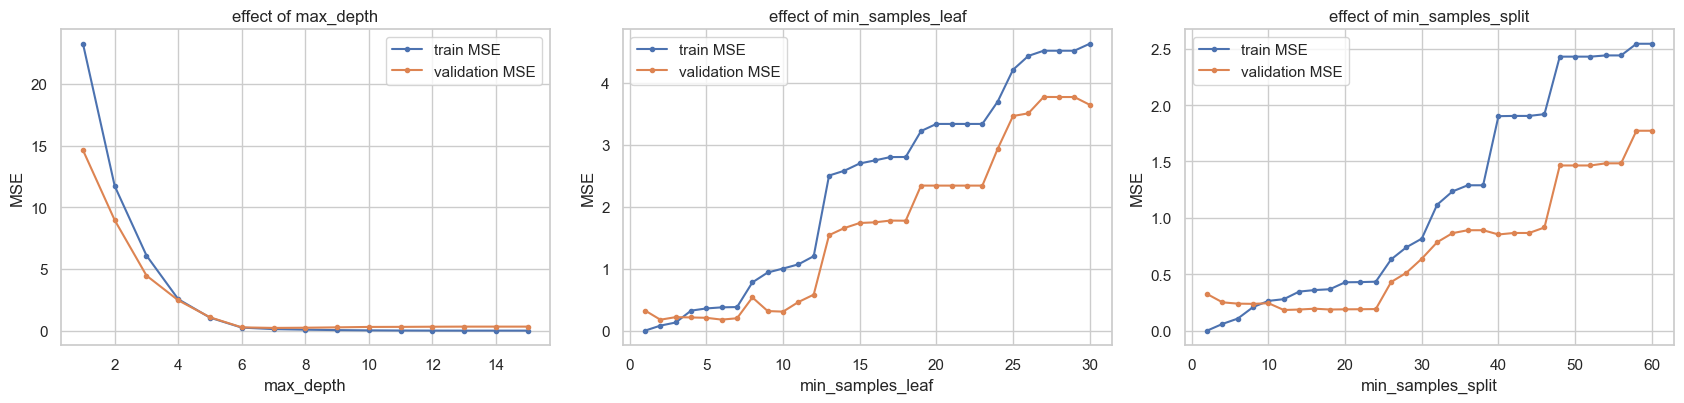

In [14]:
def val_mse(**params):
    m = DecisionTreeRegressor(random_state=SEED, **params).fit(X_tr2, y_tr2)
    return mean_squared_error(y_tr2, m.predict(X_tr2)), mean_squared_error(y_va2, m.predict(X_va2))

sweeps = {'max_depth': range(1, 16), 'min_samples_leaf': range(1, 31), 'min_samples_split': range(2, 61, 2)}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for a, (param, values) in zip(ax, sweeps.items()):
    tr, va = zip(*[val_mse(**{param: v}) for v in values])
    a.plot(list(values), tr, 'o-', ms=3, label='train MSE')
    a.plot(list(values), va, 'o-', ms=3, label='validation MSE')
    a.set_xlabel(param); a.set_ylabel('MSE'); a.set_title(f'effect of {param}'); a.legend()
plt.tight_layout(); savefig('q2_sweeps'); plt.show()

In [15]:
search = []
for d in range(2, 16):
    for leaf in [1, 2, 3, 5, 8, 12]:
        for split in [2, 5, 10, 20]:
            _, va = val_mse(max_depth=d, min_samples_leaf=leaf, min_samples_split=split)
            search.append({'max_depth': d, 'min_samples_leaf': leaf, 'min_samples_split': split, 'val_mse': va})
search = pd.DataFrame(search).sort_values('val_mse')
best = search.iloc[0][['max_depth', 'min_samples_leaf', 'min_samples_split']].astype(int).to_dict()
results['q2_best_params'] = best
results['q2_best_val_mse'] = float(search.iloc[0]['val_mse'])
print('best:', best, '| val MSE =', round(search.iloc[0]['val_mse'], 4))
search.head(8).round(4)

best: {'max_depth': 9, 'min_samples_leaf': 2, 'min_samples_split': 2} | val MSE = 0.1746


,max_depth,min_samples_leaf,min_samples_split,val_mse
172,9,2,2,0.1746
220,11,2,2,0.1762
292,14,2,2,0.1762
244,12,2,2,0.1762
316,15,2,2,0.1762
268,13,2,2,0.1762
196,10,2,2,0.1769
148,8,2,2,0.1876


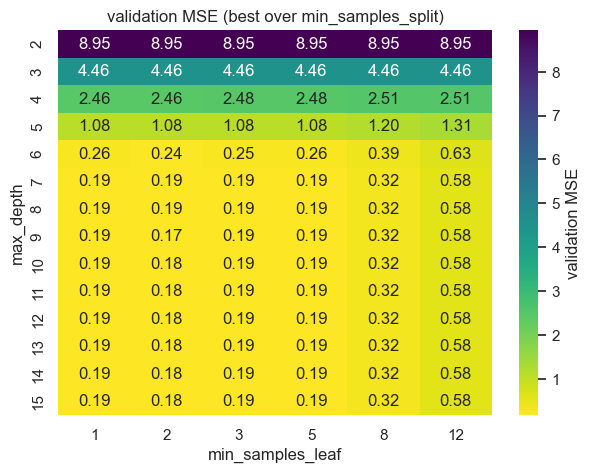

In [16]:
pivot = search.groupby(['max_depth', 'min_samples_leaf'])['val_mse'].min().unstack()
plt.figure(figsize=(7, 5))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='viridis_r', cbar_kws={'label': 'validation MSE'})
plt.title('validation MSE (best over min_samples_split)')
savefig('q2_heatmap'); plt.show()

### 3. 5-fold cross-validation with the chosen hyper-parameters, test MSE and the tree

In [17]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
fold_mse = []
for k, (tr_idx, va_idx) in enumerate(kf.split(X_tv), 1):
    m = DecisionTreeRegressor(random_state=SEED, **best).fit(X_tv[tr_idx], y_tv[tr_idx])
    fold_mse.append(mean_squared_error(y_tv[va_idx], m.predict(X_tv[va_idx])))
    print(f'fold {k}: MSE = {fold_mse[-1]:.4f}')
print(f'CV MSE = {np.mean(fold_mse):.4f} ± {np.std(fold_mse):.4f}')

final = DecisionTreeRegressor(random_state=SEED, **best).fit(X_tv, y_tv)
test_mse = mean_squared_error(y_te2, final.predict(X_te2))
results['q2'] = {'cv_fold_mse': [float(v) for v in fold_mse], 'cv_mean': float(np.mean(fold_mse)),
                 'cv_std': float(np.std(fold_mse)), 'test_mse': float(test_mse),
                 'n_leaves': int(final.get_n_leaves()), 'depth': int(final.get_depth()),
                 'y_range': [float(y_e.min()), float(y_e.max())]}
print(f'test MSE = {test_mse:.4f}  (RMSE {np.sqrt(test_mse):.3f} on a target ranging {y_e.min():.1f}–{y_e.max():.1f})')

fold 1: MSE = 0.2261
fold 2: MSE = 0.7712
fold 3: MSE = 0.2770
fold 4: MSE = 0.2973
fold 5: MSE = 0.2880
CV MSE = 0.3719 ± 0.2011
test MSE = 0.3280  (RMSE 0.573 on a target ranging 6.0–43.1)


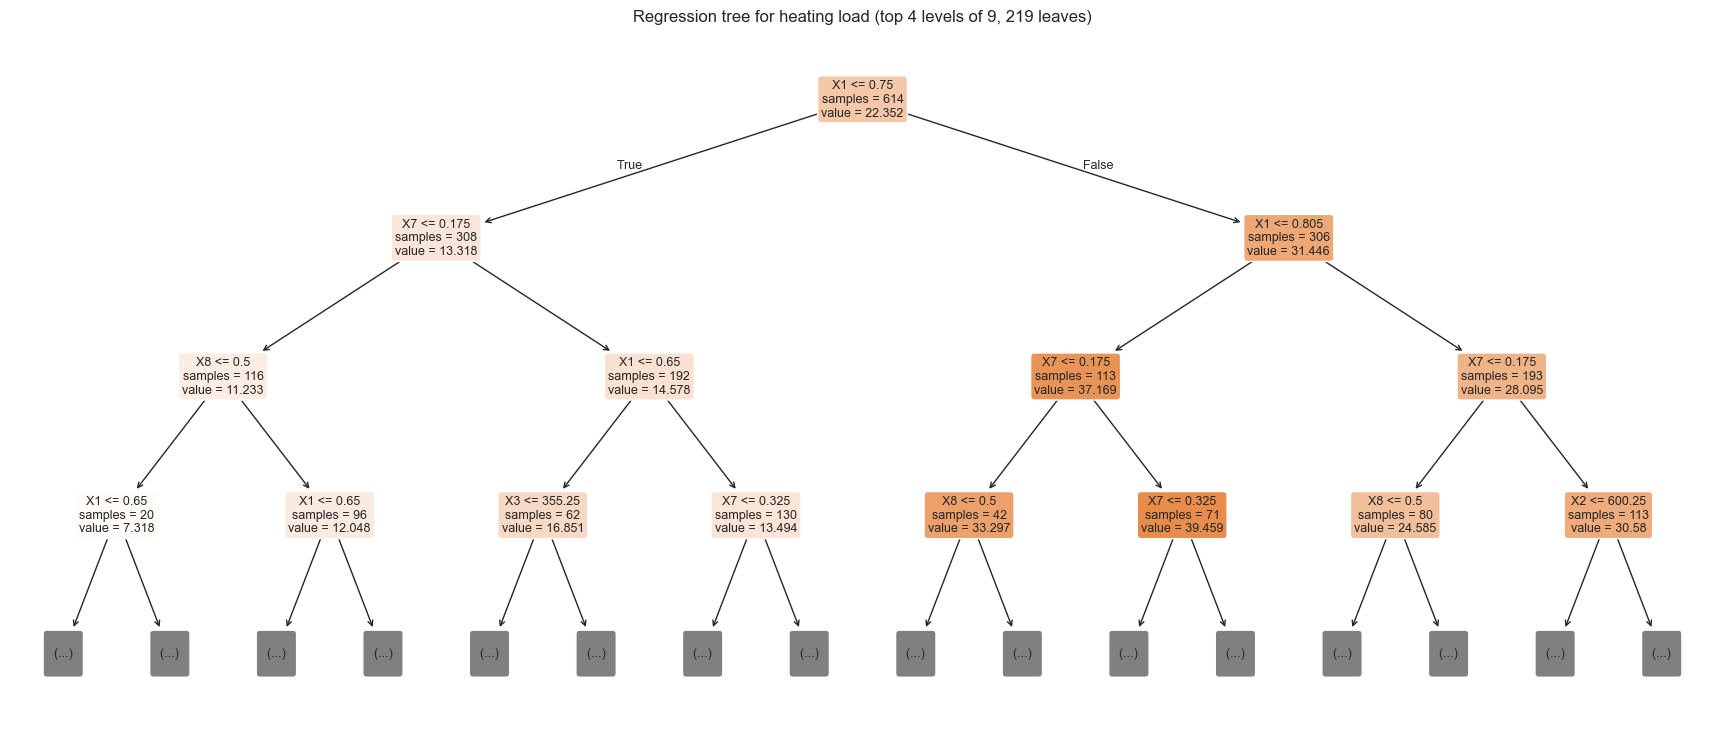

In [18]:
plt.figure(figsize=(22, 9))
plot_tree(final, feature_names=FEATS, filled=True, max_depth=3, fontsize=9, impurity=False, rounded=True)
plt.title(f'Regression tree for heating load (top 4 levels of {final.get_depth()}, {final.get_n_leaves()} leaves)')
savefig('q2_tree'); plt.show()

In [19]:
imp = pd.Series(final.feature_importances_, index=FEATS).sort_values(ascending=False)
results['q2_importance'] = imp.round(4).to_dict()
with open('results.json', 'w') as f:
    json.dump(results, f, indent=2)
imp.round(4)

X1    0.8966
X7    0.0650
X8    0.0224
X3    0.0078
X2    0.0078
X6    0.0003
X4    0.0001
X5    0.0000
dtype: float64